In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib


In [8]:
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, RepeatedStratifiedKFold,
    TimeSeriesSplit, GroupKFold, cross_val_predict, cross_val_score)


In [9]:
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve)


In [10]:
from imblearn.over_sampling import SMOTE
raw_data = pd.read_csv("allfiles/titanic.csv")

In [11]:
feature_columns = ["Pclass", "Gender", "Age", "SibSp", "Parch", "Fare"]
data = raw_data[["Survived"] + feature_columns].copy()
group_labels = raw_data.loc[data.index, "Ticket"].fillna(
    pd.Series(data.index.astype(str), index=data.index)).astype(str)


In [12]:
encoder = LabelEncoder()
data["Gender"] = encoder.fit_transform(data["Gender"].astype(str))
age_imputer = SimpleImputer(strategy="median")
data[["Age"]] = age_imputer.fit_transform(data[["Age"]])


In [13]:
X = data.drop("Survived", axis=1)
y = data["Survived"]

In [14]:
print("Dataset shape:", data.shape)
print("Original CSV shape:", raw_data.shape)
print("Feature columns:", list(X.columns))
display(data.head())


Dataset shape: (891, 7)
Original CSV shape: (891, 12)
Feature columns: ['Pclass', 'Gender', 'Age', 'SibSp', 'Parch', 'Fare']


,Survived,Pclass,Gender,Age,SibSp,Parch,Fare
0,0,3,1,22.0,1,0,7.2500
1,1,1,0,38.0,1,0,71.2833
2,1,3,0,26.0,0,0,7.9250
3,1,1,0,35.0,1,0,53.1000
4,0,3,1,35.0,0,0,8.0500


In [15]:
print("\nSurvival counts:")
print(y.value_counts())
print("\nMissing values after preprocessing:")
print(data.isna().sum())
print("\nNumber of ticket groups:", group_labels.nunique())


Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Missing values after preprocessing:
Survived    0
Pclass      0
Gender      0
Age         0
SibSp       0
Parch       0
Fare        0
dtype: int64

Number of ticket groups: 683


In [16]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)


In [17]:
depth_values = [2, 4, 6, 8, None]
results = []


In [18]:
for depth in depth_values:
    model = RandomForestClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    train_accuracy = accuracy_score(y_train, model.predict(X_train))
    val_accuracy = accuracy_score(y_val, model.predict(X_val))
    results.append([depth, train_accuracy, val_accuracy])

In [19]:
split_results = pd.DataFrame(
    results, columns=["Max Depth", "Training Accuracy", "Validation Accuracy"])
display(split_results)
best_depth = split_results.loc[
    split_results["Validation Accuracy"].idxmax(), "Max Depth"]
if pd.isna(best_depth):
    best_depth = None


,Max Depth,Training Accuracy,Validation Accuracy
0,2.0,0.792135,0.792135
1,4.0,0.844569,0.837079
2,6.0,0.891386,0.825843
3,8.0,0.923221,0.837079
4,NaN,0.986891,0.853933


In [20]:
print("Best depth:", best_depth)
best_model = RandomForestClassifier(max_depth=best_depth, random_state=42)
best_model.fit(X_train, y_train)


Best depth: None


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [21]:
print("Final training accuracy:", accuracy_score(y_train, best_model.predict(X_train)))
print("Final validation accuracy:", accuracy_score(y_val, best_model.predict(X_val)))
print("Final test accuracy:", accuracy_score(y_test, best_model.predict(X_test)))

Final training accuracy: 0.9868913857677902
Final validation accuracy: 0.8539325842696629
Final test accuracy: 0.7932960893854749


In [22]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = RandomForestClassifier(random_state=42)
predictions = cross_val_predict(model, X, y, cv=folds)
probabilities = cross_val_predict(
    model, X, y, cv=folds, method="predict_proba")[:, 1]


In [23]:
tn, fp, fn, tp = confusion_matrix(y, predictions).ravel()
accuracy = accuracy_score(y, predictions)
precision = precision_score(y, predictions, zero_division=0)
recall = recall_score(y, predictions, zero_division=0)
f1 = f1_score(y, predictions, zero_division=0)
specificity = tn / (tn + fp)
auc = roc_auc_score(y, probabilities)


In [24]:
print("Confusion Matrix:")
print(confusion_matrix(y, predictions))

Confusion Matrix:
[[476  73]
 [ 83 259]]


In [25]:
print("\nEvaluation Results")
print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-score:", round(f1, 3))
print("Specificity:", round(specificity, 3))
print("ROC-AUC:", round(auc, 3))


Evaluation Results
Accuracy: 0.825
Precision: 0.78
Recall: 0.757
F1-score: 0.769
Specificity: 0.867
ROC-AUC: 0.871


In [26]:
comparison_model = RandomForestClassifier(
    n_estimators=100, random_state=42)
comparison_results = []
X_train_ho, X_test_ho, y_train_ho, y_test_ho = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)


In [27]:
holdout_model = RandomForestClassifier(n_estimators=100, random_state=42)
holdout_model.fit(X_train_ho, y_train_ho)
holdout_accuracy = accuracy_score(y_test_ho, holdout_model.predict(X_test_ho))


In [28]:
comparison_results.append({
    "Method": "Hold-Out",
    "Mean Accuracy": holdout_accuracy,
    "Std Accuracy": 0.0,
    "Number of Test Splits": 1})

In [29]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
kfold_scores = cross_val_score(
    comparison_model, X, y, cv=kfold, scoring="accuracy")


In [30]:
comparison_results.append({
    "Method": "K-Fold",
    "Mean Accuracy": kfold_scores.mean(),
    "Std Accuracy": kfold_scores.std(),
    "Number of Test Splits": len(kfold_scores)})

In [31]:
stratified_folds = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42)
stratified_scores = cross_val_score(
    comparison_model, X, y, cv=stratified_folds, scoring="accuracy")


In [32]:
comparison_results.append({
    "Method": "Stratified K-Fold",
    "Mean Accuracy": stratified_scores.mean(),
    "Std Accuracy": stratified_scores.std(),
    "Number of Test Splits": len(stratified_scores)})

In [33]:
repeated_folds = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=42)
repeated_scores = cross_val_score(
    comparison_model, X, y, cv=repeated_folds, scoring="accuracy")


In [34]:
comparison_results.append({
    "Method": "Repeated K-Fold",
    "Mean Accuracy": repeated_scores.mean(),
    "Std Accuracy": repeated_scores.std(),
    "Number of Test Splits": len(repeated_scores)})

In [35]:
time_folds = TimeSeriesSplit(n_splits=5)
time_scores = cross_val_score(
    comparison_model, X.reset_index(drop=True), y.reset_index(drop=True),
    cv=time_folds, scoring="accuracy")


In [36]:
comparison_results.append({
    "Method": "Time Series Split (row order demo)",
    "Mean Accuracy": time_scores.mean(),
    "Std Accuracy": time_scores.std(),
    "Number of Test Splits": len(time_scores)})

In [37]:
if group_labels.nunique() >= 5:
    group_folds = GroupKFold(n_splits=5)
    group_scores = cross_val_score(
        comparison_model, X, y, cv=group_folds,
        groups=group_labels, scoring="accuracy"
    )
    comparison_results.append({
        "Method": "Group K-Fold (Ticket groups)",
        "Mean Accuracy": group_scores.mean(),
        "Std Accuracy": group_scores.std(),
        "Number of Test Splits": len(group_scores)
    })
else:
    print("Group K-Fold skipped: fewer than 5 unique groups are available.")


In [38]:
cv_comparison_table = pd.DataFrame(comparison_results)
display(cv_comparison_table.round(3))

,Method,Mean Accuracy,Std Accuracy,Number of Test Splits
0,Hold-Out,0.810,0.000,1
1,K-Fold,0.815,0.015,5
2,Stratified K-Fold,0.825,0.022,5
3,Repeated K-Fold,0.819,0.018,15
4,Time Series Split (row order demo),0.792,0.045,5
5,Group K-Fold (Ticket groups),0.804,0.017,5


Text(0, 0.5, 'Mean Accuracy')

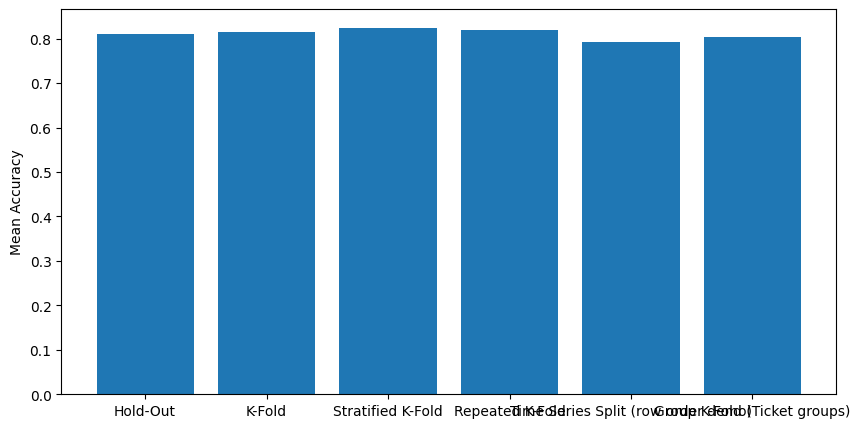

In [39]:
plt.figure(figsize=(10, 5))
plt.bar(
    cv_comparison_table["Method"],
    cv_comparison_table["Mean Accuracy"])
plt.ylabel("Mean Accuracy")


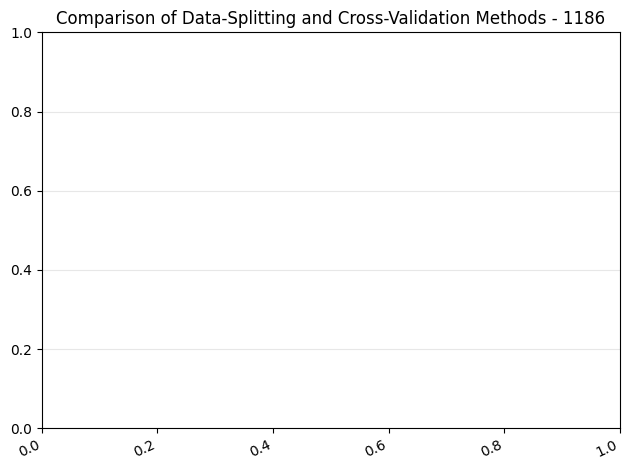

In [40]:
plt.title("Comparison of Data-Splitting and Cross-Validation Methods - 1186")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
fpr, tpr, thresholds = roc_curve(y, probabilities)


Text(0, 0.5, 'True Positive Rate')

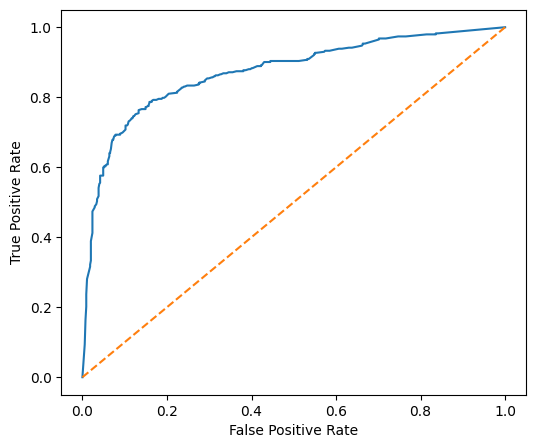

In [42]:
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")


C:\Users\hamza\AppData\Local\Temp\ipykernel_16620\43335890.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


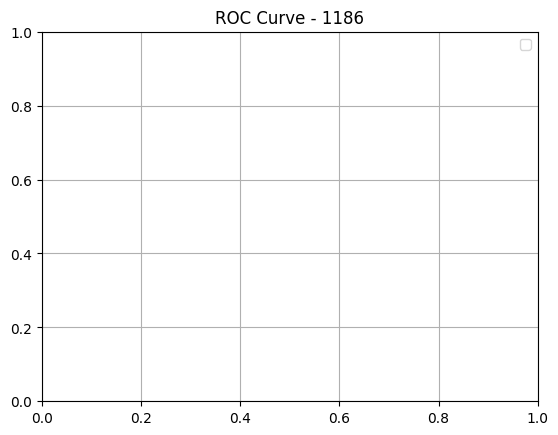

ROC-AUC: 0.871


In [43]:
plt.title("ROC Curve - 1186")
plt.legend()
plt.grid(True)
plt.show()
print("ROC-AUC:", round(roc_auc_score(y, probabilities), 3))

In [44]:
threshold_results = []
for threshold in np.arange(0.1, 1.0, 0.1):
    threshold_predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, threshold_predictions).ravel()
    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y, threshold_predictions),
        "Precision": precision_score(y, threshold_predictions, zero_division=0),
        "Recall": recall_score(y, threshold_predictions, zero_division=0),
        "F1-score": f1_score(y, threshold_predictions, zero_division=0),
        "Specificity": tn / (tn + fp)
    })


In [45]:
threshold_table = pd.DataFrame(threshold_results)
display(threshold_table)


,Threshold,Accuracy,Precision,Recall,F1-score,Specificity
0,0.1,0.652076,0.527304,0.903509,0.665948,0.495446
1,0.2,0.737374,0.610656,0.871345,0.718072,0.653916
2,0.3,0.785634,0.681055,0.830409,0.748353,0.757741
3,0.4,0.812570,0.738420,0.792398,0.764457,0.825137
4,0.5,0.827160,0.781437,0.763158,0.772189,0.867031
5,0.6,0.824916,0.812081,0.707602,0.756250,0.897996
6,0.7,0.822671,0.862205,0.640351,0.734899,0.936248
7,0.8,0.810325,0.894977,0.573099,0.698752,0.958106
8,0.9,0.766554,0.918750,0.429825,0.585657,0.976321


In [46]:
best_row = threshold_table.loc[threshold_table["F1-score"].idxmax()]


In [47]:
print("Best threshold:", best_row["Threshold"])
print("Best F1-score:", round(best_row["F1-score"], 3))

Best threshold: 0.5
Best F1-score: 0.772


In [48]:
depth_values = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, None]
depth_results = []
depth_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [49]:
for max_depth in depth_values:
    decision_tree = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    decision_tree.fit(X, y)
    training_accuracy = accuracy_score(y, decision_tree.predict(X))
    cross_validation_accuracy = cross_val_score(decision_tree, X, y, cv=depth_folds).mean()
    depth_results.append({
        "Max Depth": str(max_depth),
        "Training Accuracy": training_accuracy,
        "Cross-validation Accuracy": cross_validation_accuracy
    })


In [50]:
depth_accuracy_table = pd.DataFrame(depth_results)
display(depth_accuracy_table)

,Max Depth,Training Accuracy,Cross-validation Accuracy
0,1,0.786756,0.786755
1,2,0.795735,0.776637
2,3,0.827160,0.824907
3,4,0.835017,0.821537
4,5,0.840629,0.817042
5,6,0.868687,0.820400
6,7,0.878788,0.824920
7,8,0.893378,0.828303
8,9,0.903479,0.821555
9,10,0.910213,0.813709


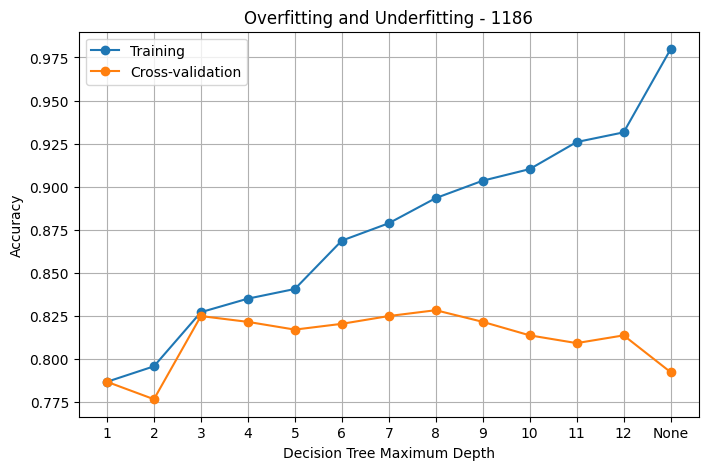

In [66]:
plt.figure(figsize=(8, 5))
plt.plot(depth_accuracy_table["Max Depth"], depth_accuracy_table["Training Accuracy"], marker="o", label="Training")
plt.plot(depth_accuracy_table["Max Depth"], depth_accuracy_table["Cross-validation Accuracy"], marker="o", label="Cross-validation")
plt.xlabel("Decision Tree Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Overfitting and Underfitting - 1186")
plt.legend()
plt.grid(True)
plt.show()


In [54]:
died = data[data["Survived"] == 0]
survivors = data[data["Survived"] == 1].sample(47, random_state=42)
imbalanced_data = pd.concat([died, survivors]).sample(frac=1, random_state=42)


In [55]:
X_imb = imbalanced_data.drop("Survived", axis=1)
y_imb = imbalanced_data["Survived"]


In [56]:
print("Class counts:")
print(y_imb.value_counts())
print("Survivor percentage:", round(y_imb.mean() * 100, 2), "%")

Class counts:
Survived
0    549
1     47
Name: count, dtype: int64
Survivor percentage: 7.89 %


In [57]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_index, test_index = next(folds.split(X_imb, y_imb))
X_train = X_imb.iloc[train_index]
y_train = y_imb.iloc[train_index]


In [58]:
print("Before SMOTE:")
print(y_train.value_counts())
smote = SMOTE(random_state=42)


Before SMOTE:
Survived
0    439
1     37
Name: count, dtype: int64


In [59]:
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)
print("\nAfter SMOTE:")
print(pd.Series(y_train_balanced).value_counts())


After SMOTE:
Survived
0    439
1    439
Name: count, dtype: int64


In [60]:
final_model = RandomForestClassifier(
    max_depth=best_depth,
    n_estimators=100,
    random_state=42)
final_model.fit(X, y)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [61]:
model_bundle = {
    "model": final_model,
    "gender_encoder": encoder,
    "age_imputer": age_imputer,
    "feature_columns": list(X.columns),
    "target_name": "Survived"}


In [62]:
joblib.dump(model_bundle, "titanic_random_forest_model.joblib")
print("Final model saved as titanic_random_forest_model.joblib")


Final model saved as titanic_random_forest_model.joblib


In [63]:
loaded_bundle = joblib.load("titanic_random_forest_model.joblib")
loaded_model = loaded_bundle["model"]


In [64]:
print("Loaded model prediction for the first passenger:", loaded_model.predict(X.iloc[[0]]))

Loaded model prediction for the first passenger: [0]
